# Raqeeb – Weapon Detection (YOLO11n)

This notebook trains and evaluates the weapon detection model of Raqeeb, a wearable AI device that alerts police officers to threats in real time. The model detects pistols and knives in the frames captured by the device camera.

- Dataset: Weapon Detection Dataset, Kaggle (`mehmetcubukcu/weapon-detection`), CC BY-SA 4.0
- Model: YOLO11n, chosen because it runs in real time on the Raspberry Pi 5
- Training: the pretrained YOLO11n is trained on the dataset (Cell 3) and then fine-tuned for real-world conditions, such as different angles, distances and lighting (Cell 4)
- Final model: `MyDrive/Raqeeb/yolo/weapon_v1_1/weights/best.pt`
- Alert rule used by the device: a pistol or knife detected with a confidence of 0.40 or higher in 3 consecutive frames

| Cell | Content |
|---|---|
| 1 | Session setup |
| 2 | Class distribution |
| 3 | Training |
| 4 | Fine-tuning |
| 5 | Test evaluation |
| 6 | Confusion matrix |
| 7 | Alert threshold selection |
| 8 | Live test with the laptop camera |

Run Cell 1 first every time the notebook is opened.

### Cell 1 – Session setup
Installs the libraries, mounts Google Drive, downloads the dataset from Kaggle, creates `data.yaml` and loads the final model into `best`. Takes about 2 minutes.

The original class names in the dataset are in Spanish and are renamed here to `pistol, smartphone, knife, purse, bill, card`. Class IDs: 0 = pistol, 2 = knife.

Select a GPU runtime first: Runtime › Change runtime type › T4 GPU.

In [ ]:
!pip install -q kagglehub ultralytics
import kagglehub, os, glob, yaml
from google.colab import drive
from ultralytics import YOLO

drive.mount('/content/drive')

path = kagglehub.dataset_download("mehmetcubukcu/weapon-detection")
root = os.path.dirname(glob.glob(f"{path}/**/data.yaml", recursive=True)[0])
cfg = {
    "path": root,
    "train": "train/images", "val": "val/images", "test": "test/images",
    "names": ["pistol", "smartphone", "knife", "purse", "bill", "card"], "nc": 6,
}
yaml.safe_dump(cfg, open("/content/data.yaml", "w"))

STAGE1_MODEL = "/content/drive/MyDrive/Raqeeb/yolo/weapon_v1/weights/best.pt"
FINAL_MODEL = "/content/drive/MyDrive/Raqeeb/yolo/weapon_v1_1/weights/best.pt"
best = YOLO(FINAL_MODEL)
print("Setup complete.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive


100%|██████████| 1.71G/1.71G [01:32<00:00, 19.9MB/s]

Extracting files...


Setup complete.


### Cell 2 – Class distribution

| Class | train | val | test |
|---|---|---|---|
| knife | 1,825 | 241 | 211 |
| pistol | 1,425 | 50 | 35 |
| smartphone | 575 | 58 | 82 |
| purse | 530 | 38 | 33 |
| bill | 425 | 28 | 24 |
| card | 222 | 35 | 22 |
| Total | 5,002 | 450 | 407 |

Every image contains exactly one object. The non-weapon classes help the model tell weapons apart from objects that are commonly held in the hand. Card is the smallest class, and the test set has only 35 pistols, so the pistol metrics can vary.

In [ ]:
from collections import Counter
names = cfg["names"]
for split in ["train", "val", "test"]:
    c = Counter()
    for f in glob.glob(f"{root}/{split}/labels/*.txt"):
        for line in open(f):
            if line.strip(): c[int(line.split()[0])] += 1
    print(split, {names[k]: v for k, v in sorted(c.items())})

train {'pistol': 1425, 'smartphone': 575, 'knife': 1825, 'purse': 530, 'bill': 425, 'card': 222}
val {'pistol': 50, 'smartphone': 58, 'knife': 241, 'purse': 38, 'bill': 28, 'card': 35}
test {'pistol': 35, 'smartphone': 82, 'knife': 211, 'purse': 33, 'bill': 24, 'card': 22}


### Cell 3 – Training
Trains the pretrained YOLO11n on the dataset.
- 50 epochs, image size 640, batch 16, about 1 hour and 20 minutes on a T4 GPU
- Weights saved in `MyDrive/Raqeeb/yolo/weapon_v1/weights/best.pt`

The trained weights are already saved in Drive, so training runs only when `RUN_TRAINING = True`.

In [ ]:
RUN_TRAINING = False

if RUN_TRAINING:
    model = YOLO("yolo11n.pt")
    model.train(
        data="/content/data.yaml",
        epochs=50,
        imgsz=640,
        batch=16,
        project="/content/drive/MyDrive/Raqeeb/yolo",
        name="weapon_v1",
    )
else:
    print("Trained weights:", STAGE1_MODEL)

Trained weights: /content/drive/MyDrive/Raqeeb/yolo/weapon_v1/weights/best.pt


### Cell 4 – Fine-tuning for real-world conditions
The dataset images are mostly close-up photos with one object each, while the Raqeeb camera sees wider scenes with smaller objects, different angles, motion and lighting. Fine-tuning continues from the trained weights of Cell 3 to make the model more robust in these conditions:
- `cls=1.0` (default 0.5) gives more weight to classification errors, for example a weapon labelled as a smartphone.
- Augmentation that imitates the body camera: rotation, scale, translation, perspective, brightness and mixup.
- A small learning rate (`lr0=0.001`) so the model builds on what it has already learned.
- Up to 40 epochs, stopping early if validation mAP does not improve for 15 epochs. About 1–1.5 minutes per epoch on a T4 GPU.

The result is the final model, saved in `MyDrive/Raqeeb/yolo/weapon_v1_1/weights/best.pt`. If the session disconnects during training, run Cell 1 and then the resume line at the end of this cell.

In [ ]:
RUN_TRAINING = False

if RUN_TRAINING:
    model = YOLO(STAGE1_MODEL)
    model.train(
        data="/content/data.yaml",
        epochs=40,
        patience=15,          # stop early if mAP does not improve for 15 epochs
        imgsz=640,
        batch=16,
        optimizer="AdamW",
        lr0=0.001,            # small learning rate for fine-tuning
        warmup_epochs=1,
        cos_lr=True,
        cls=1.0,              # weigh classification errors more (default 0.5)
        degrees=10,           # small rotations (camera tilt while walking)
        translate=0.15,
        scale=0.6,            # objects appear smaller or bigger (distance)
        perspective=0.0005,   # wide-angle lens distortion
        hsv_v=0.5,            # brighter or darker scenes
        mixup=0.1,
        close_mosaic=10,
        save_period=10,
        project="/content/drive/MyDrive/Raqeeb/yolo",
        name="weapon_v1_1",
    )
    # To resume after a disconnection:
    # YOLO("/content/drive/MyDrive/Raqeeb/yolo/weapon_v1_1/weights/last.pt").train(resume=True)
else:
    print("Final model weights:", FINAL_MODEL)

Final model weights: /content/drive/MyDrive/Raqeeb/yolo/weapon_v1_1/weights/best.pt


### Cell 5 – Test evaluation
Evaluates the final model on the test set (407 images that were not used in training or model selection).
- Precision: the share of detections that are correct.
- Recall: the share of objects that the model detects.
- mAP50: mean average precision when a detection counts as correct if its box overlaps the true box by at least 50%.
- mAP50-95: the same, averaged over stricter overlaps from 50% to 95%.

In [ ]:
def evaluate(weights):
    r = YOLO(weights).val(data="/content/data.yaml", split="test", plots=False, verbose=False)
    idx = list(r.box.ap_class_index)
    rows = {}
    for cls_id, name in [(0, "pistol"), (2, "knife")]:
        p, rc, ap50, ap = r.box.class_result(idx.index(cls_id))
        rows[name] = (p, rc, ap50, ap)
    rows["all classes"] = (r.box.mp, r.box.mr, r.box.map50, r.box.map)
    return rows

final = evaluate(FINAL_MODEL)
print("Final model – test set")
print(f"{'class':<12} | precision | recall | mAP50 | mAP50-95")
for name, (p, rc, ap50, ap) in final.items():
    print(f"{name:<12} |   {p:.3f}   | {rc:.3f}  | {ap50:.3f} |  {ap:.3f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2120.2±1100.0 MB/s, size: 464.5 KB)
val: Scanning /root/.cache/kagglehub/datasets/mehmetcubukcu/weapon-detection/versions/1/weapon-detection/test/labels... 407 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 407/407 1.4Kit/s 0.3s
val: New cache created: /root/.cache/kagglehub/datasets/mehmetcubukcu/weapon-detection/versions/1/weapon-detection/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 4.0it/s 6.5s
                   all        407        407      0.867      0.796      0.891      0.667
Speed: 1.1ms preprocess, 3.8ms inference, 0.0ms loss, 2.0ms postprocess per image
Final model – test set
class        | precision | recall | mAP50 | mAP50-95
pistol       |   0.886   | 0.971  | 0.976 

### Cell 6 – Confusion matrix
Shows how often each class is predicted as each other class on the test set. Columns are the true class and rows are the predicted class. The important cells are pistol and knife predicted as a non-weapon class or as background, because these would be missed alerts.

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3002.9±822.0 MB/s, size: 374.1 KB)
val: Scanning /root/.cache/kagglehub/datasets/mehmetcubukcu/weapon-detection/versions/1/weapon-detection/test/labels.cache... 407 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 407/407 74.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 3.9it/s 6.7s
                   all        407        407      0.867      0.796      0.891      0.667
Speed: 1.3ms preprocess, 3.9ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/drive/MyDrive/Raqeeb/yolo/weapon_final_test


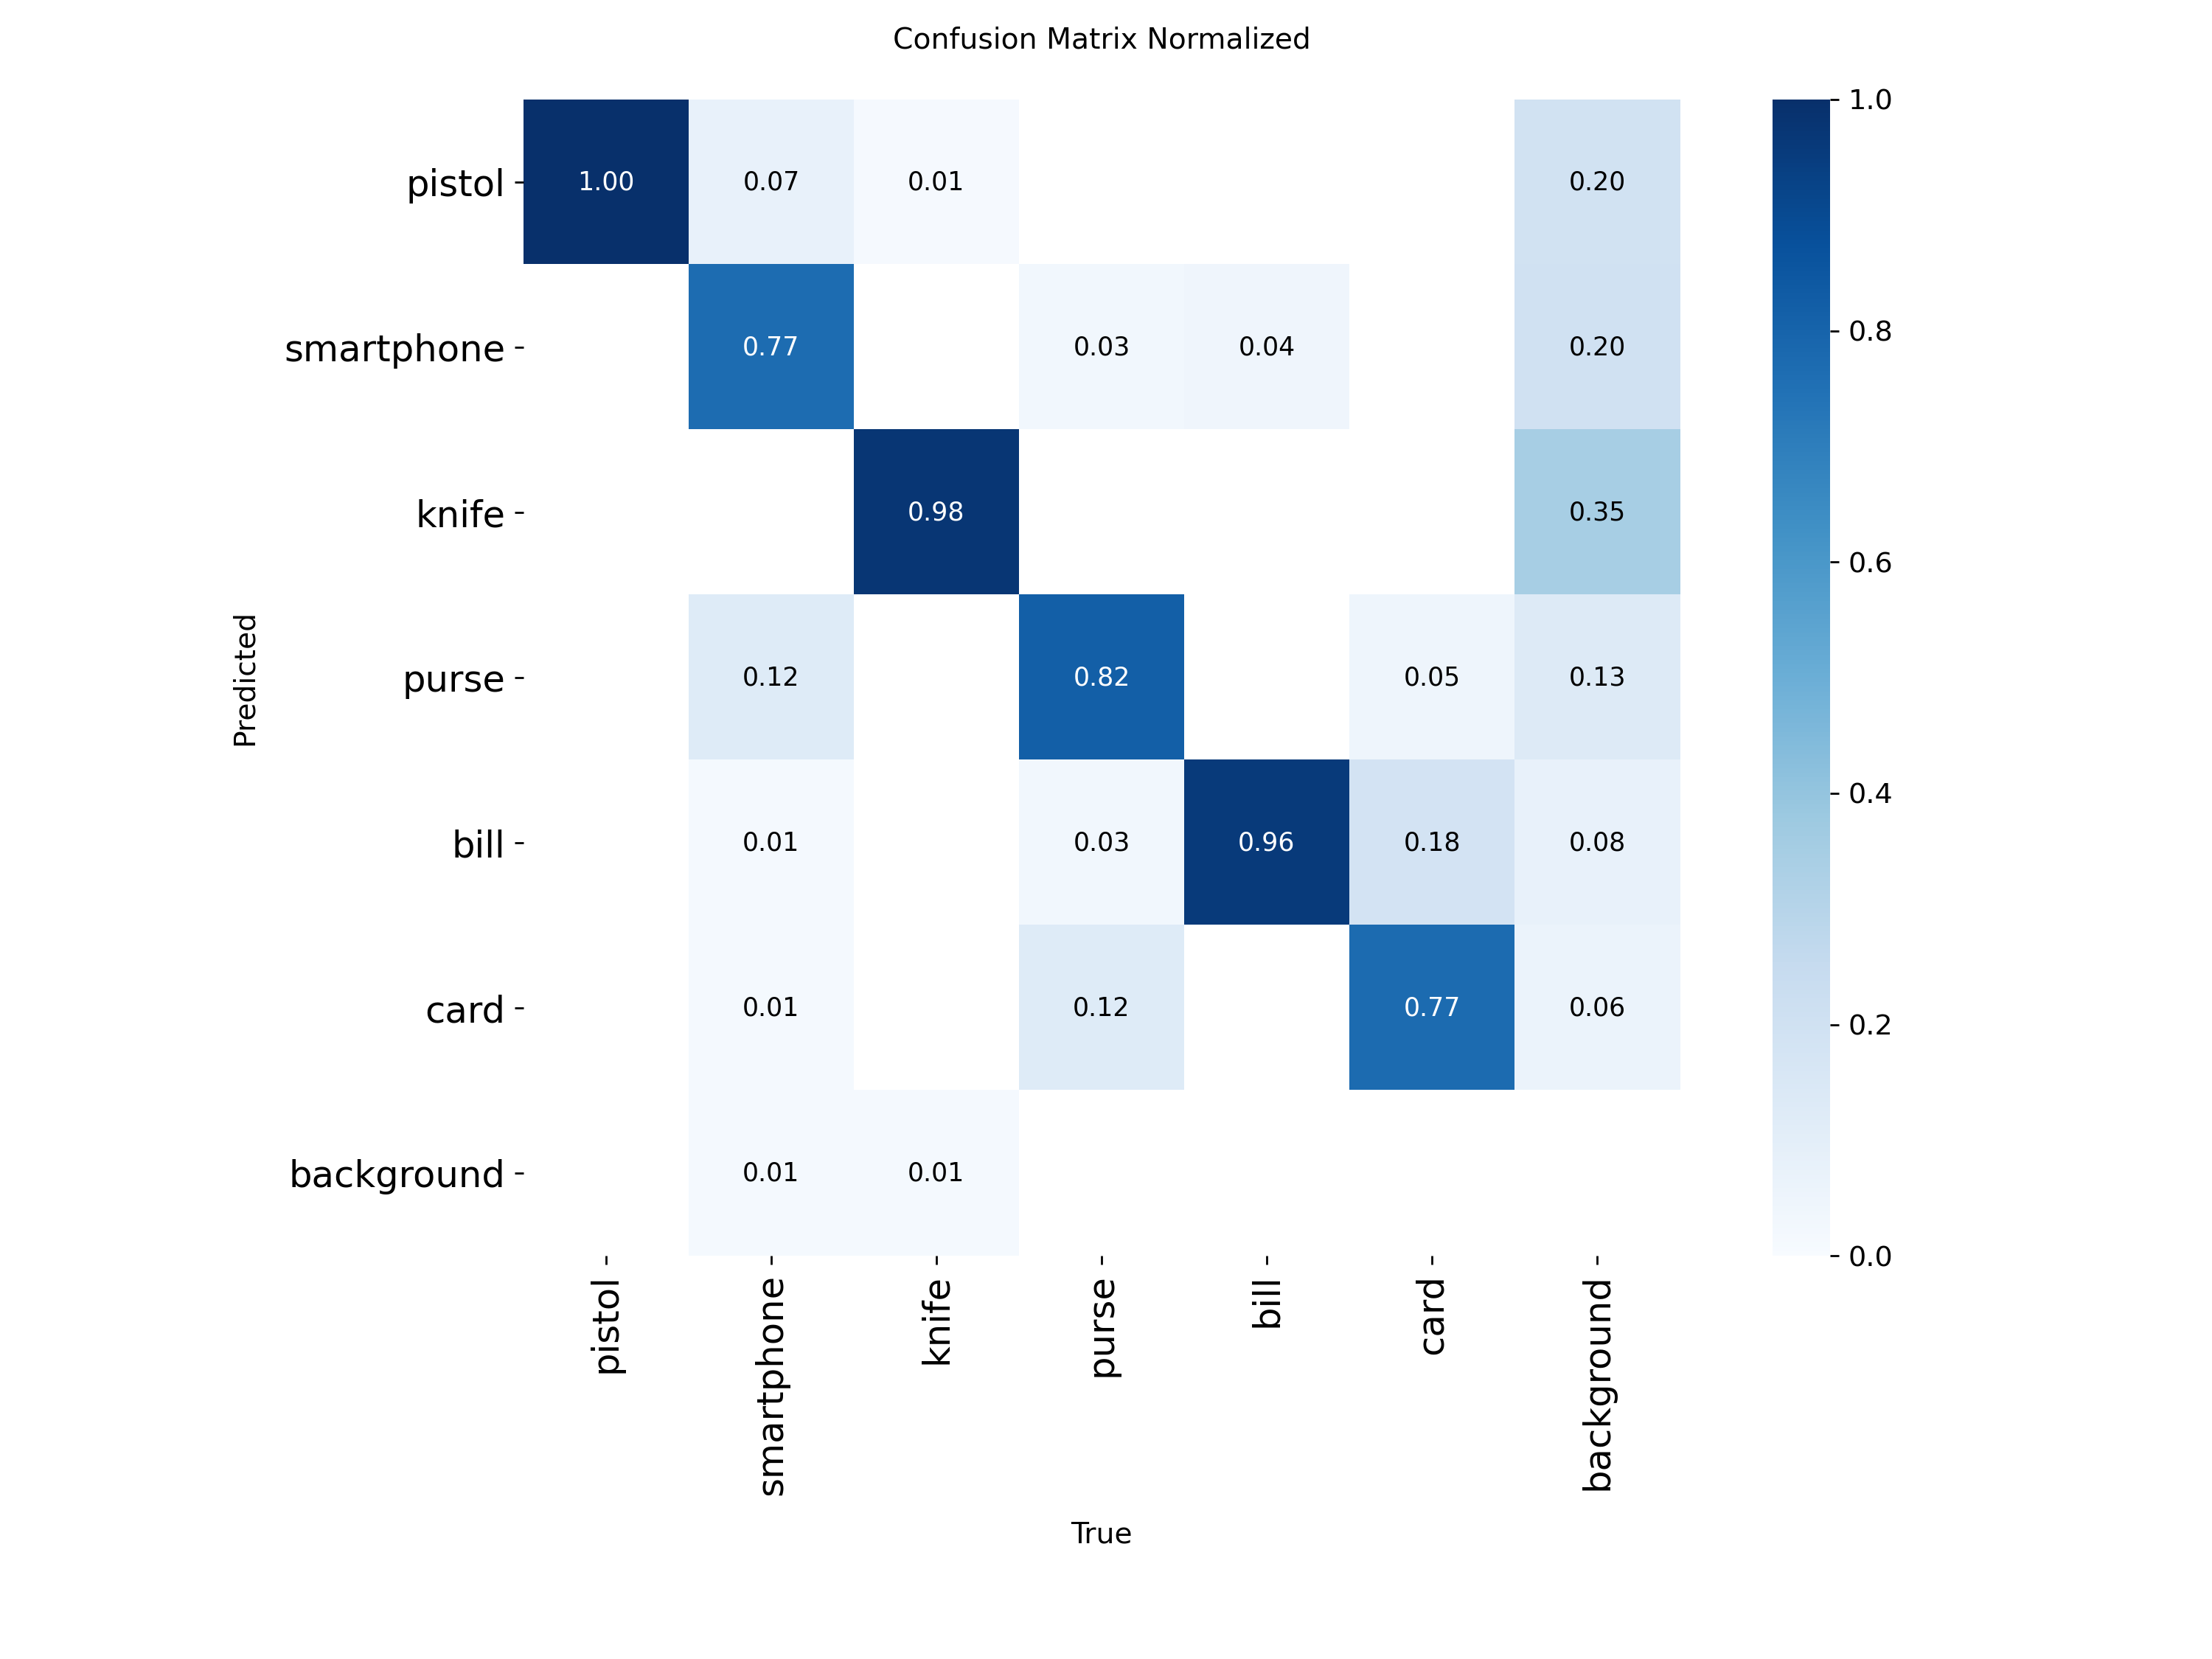

In [ ]:
from IPython.display import Image, display
best.val(data="/content/data.yaml", split="test", verbose=False,
         project="/content/drive/MyDrive/Raqeeb/yolo", name="weapon_final_test", exist_ok=True)
display(Image("/content/drive/MyDrive/Raqeeb/yolo/weapon_final_test/confusion_matrix_normalized.png", width=700))

### Cell 7 – Alert threshold selection
Tests different confidence thresholds on the test set, using the device's alert rule: alert if a pistol or knife is detected above the threshold. For each threshold it reports precision and recall for pistols, knives and weapons in general, the number of false alarms and the number of missed weapons.

Raqeeb uses a threshold of 0.40, which keeps false alarms low while missing very few weapons. A single wrong frame does not raise an alert, because the device also requires the weapon to appear in 3 consecutive frames (Cell 8).

In [ ]:
import os, glob

imgs = sorted(glob.glob(f"{root}/test/images/*"))
rows = []
for r in best.predict(imgs, conf=0.05, verbose=False, stream=True):
    lbl = os.path.splitext(r.path.replace("/images/", "/labels/"))[0] + ".txt"
    gt = {int(l.split()[0]) for l in open(lbl) if l.strip()}
    mx = {0: 0.0, 2: 0.0}  # 0 = pistol, 2 = knife
    for c, f in zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()):
        if c in mx: mx[c] = max(mx[c], f)
    rows.append((gt, mx))

def score(t, k):
    tp = fp = fn = 0
    for gt, mx in rows:
        if k == "weapon":
            g, a = bool(gt & {0, 2}), max(mx.values()) >= t
        else:
            g, a = k in gt, mx[k] >= t
        tp += g and a; fp += (not g) and a; fn += g and (not a)
    p = tp / (tp + fp) if tp + fp else 0
    r = tp / (tp + fn) if tp + fn else 0
    return p, r, fp, fn

print(" conf | pistol P   R  | knife P   R  | weapon P   R  | false alarms | missed weapons")
for t in [0.25, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pp, pr, _, _ = score(t, 0); kp, kr, _, _ = score(t, 2); wp, wr, wfp, wfn = score(t, "weapon")
    print(f" {t:.2f} |   {pp:.2f}  {pr:.2f}  |  {kp:.2f}  {kr:.2f} |   {wp:.2f}  {wr:.2f}  |     {wfp:3d}      |      {wfn:3d}")

 conf | pistol P   R  | knife P   R  | weapon P   R  | false alarms | missed weapons
 0.25 |   0.70  1.00  |  1.00  0.94 |   0.95  0.96  |      12      |       10
 0.30 |   0.73  1.00  |  1.00  0.94 |   0.96  0.96  |      10      |       11
 0.40 |   0.81  0.97  |  1.00  0.93 |   0.97  0.94  |       6      |       14
 0.50 |   0.85  0.97  |  1.00  0.91 |   0.98  0.92  |       4      |       19
 0.60 |   0.87  0.94  |  1.00  0.86 |   0.99  0.88  |       3      |       30
 0.70 |   0.91  0.91  |  1.00  0.72 |   0.99  0.75  |       2      |       62


### Cell 8 – Live test with the laptop camera
Runs the final model on the laptop camera to simulate the device. The video plays in the browser and the detection boxes are drawn on top of it as frames are processed.
- Alert rule, as on the device: WEAPON ALERT when the same weapon class (pistol or knife) is detected with a confidence of 0.40 or higher in 3 consecutive frames. If both are confirmed at the same time, one alert lists both.
- Red boxes are weapons and blue boxes are other classes.
- Optional: set `SAVE_EVERY = 10` to save every 10th frame to `MyDrive/Raqeeb/real_frames/`, to collect real-world images for future training.
- Click Stop Raqeeb to finish. If the camera does not start, allow camera access for Colab in the browser.


In [ ]:
import os, json, time, cv2, numpy as np, io, base64
from collections import deque
from PIL import Image as PILImage
from IPython.display import display, Javascript
from google.colab.output import eval_js

MODEL = FINAL_MODEL
SAVE_EVERY = 0                                   # e.g. 10 = save every 10th frame for labelling, 0 = off
SAVE_DIR = "/content/drive/MyDrive/Raqeeb/real_frames"
WEAPONS = {0, 2}                                 # 0 = pistol, 2 = knife
WEAPON_CONF = 0.4

live = YOLO(MODEL)
names = live.names

display(Javascript('''
var video = null, div = null, stream = null, canvas = null, overlay = null, label = null;
var pendingResolve = null, shutdown = false;

function removeDom() {
  stream.getVideoTracks()[0].stop();
  div.remove(); video = div = stream = canvas = overlay = label = null;
}

function onFrame() {
  if (!shutdown) window.requestAnimationFrame(onFrame);
  if (pendingResolve) {
    var result = "";
    if (!shutdown) {
      canvas.getContext("2d").drawImage(video, 0, 0, canvas.width, canvas.height);
      result = canvas.toDataURL("image/jpeg", 0.8);
    }
    var r = pendingResolve; pendingResolve = null; r(result);
  }
}

async function createDom() {
  if (div !== null) return;
  div = document.createElement("div");
  div.style.cssText = "position:relative; width:640px;";
  label = document.createElement("div");
  label.style.cssText = "font:600 18px sans-serif; padding:6px 0;";
  label.textContent = "Starting camera...";
  video = document.createElement("video");
  video.style.cssText = "display:block; width:640px;";
  video.setAttribute("playsinline", "");
  video.muted = true;
  overlay = document.createElement("img");
  overlay.style.cssText = "position:absolute; left:0; width:640px; pointer-events:none;";
  var btn = document.createElement("button");
  btn.textContent = "Stop Raqeeb";
  btn.style.cssText = "margin-top:8px;";
  btn.onclick = () => { shutdown = true; };
  div.appendChild(label); div.appendChild(video); div.appendChild(overlay); div.appendChild(btn);
  document.body.appendChild(div);
  stream = await navigator.mediaDevices.getUserMedia({video: true});
  video.srcObject = stream;
  await video.play();
  canvas = document.createElement("canvas");
  canvas.width = 640;
  canvas.height = Math.round(640 * video.videoHeight / video.videoWidth);
  overlay.style.top = label.offsetHeight + "px";
  overlay.style.height = canvas.height + "px";
  window.requestAnimationFrame(onFrame);
}

window.stream_frame = async function(text, boxes) {
  if (shutdown) { removeDom(); shutdown = false; return ""; }
  await createDom();
  if (text !== "") label.textContent = text;
  if (boxes !== "") overlay.src = boxes;
  return await new Promise(resolve => { pendingResolve = resolve; });
};
'''))

def to_frame(data_url):
    return cv2.imdecode(np.frombuffer(base64.b64decode(data_url.split(",")[1]), np.uint8), cv2.IMREAD_COLOR)

def to_png(rgba):
    buf = io.BytesIO(); PILImage.fromarray(rgba).save(buf, format="png")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()

if SAVE_EVERY: os.makedirs(SAVE_DIR, exist_ok=True)
last = deque(maxlen=3)           # the last 3 processed frames
text, boxes, n = "", "", 0
print("Live test started. Click Stop Raqeeb to finish.")
while True:
    reply = eval_js(f"stream_frame({json.dumps(text)}, {json.dumps(boxes)})")
    if not reply:
        break
    frame = to_frame(reply); n += 1
    if SAVE_EVERY and n % SAVE_EVERY == 0:
        cv2.imwrite(f"{SAVE_DIR}/frame_{int(time.time()*1000)}.jpg", frame)

    r = live.predict(frame, conf=0.25, verbose=False)[0]
    overlay = np.zeros((frame.shape[0], frame.shape[1], 4), np.uint8)
    hits = set()                    # weapon classes found in this frame
    for (x1, y1, x2, y2), c, s in zip(r.boxes.xyxy.int().tolist(), r.boxes.cls.int().tolist(), r.boxes.conf.tolist()):
        weapon = c in WEAPONS
        if weapon and s >= WEAPON_CONF:
            hits.add(c)
        color = (220, 30, 30, 255) if weapon else (30, 120, 220, 255)
        cv2.rectangle(overlay, (x1, y1), (x2, y2), color, 2)
        cv2.putText(overlay, f"{names[c]} {s:.2f}", (x1, max(15, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    last.append(hits)
    confirmed = set.intersection(*last) if len(last) == 3 else set()   # same class in 3 consecutive frames
    alert = bool(confirmed)
    text = f"WEAPON ALERT: {', '.join(names[c] for c in confirmed)}" if alert else "Monitoring"
    boxes = to_png(overlay)
print("Live test stopped.", f"{n} frames processed.")
